# Assignment 3 — Think First, Then Code (Variant A)
**Linear, Logistic, and Softmax Regression for Software Engineering**

Structure of every question: **Think first** (reasoning written before running code) → **Code** → **Compare** (results vs. expectation).
All numerical results are rounded to three decimals.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, log_loss

np.set_printoptions(precision=3, suppress=True)
r3 = lambda v: np.round(v, 3)

---
# Part I. Linear Regression
## Question 1 — Code-review time

### Think first
1. **Input / target.** Input $x$ = pull-request size (hundreds of changed lines). Target $y$ = review time in minutes.
2. **Sign of the slope.** Positive. A bigger PR has more lines to read, more logic to verify and more comments to write, so review time should grow with size. The table already shows $y$ increasing at every step (roughly +7–9 min per 100 lines).
3. **Which prediction to trust.** $x = 5.5$ is safer: it lies **inside** the observed range $[1, 8]$ (interpolation), surrounded by data on both sides. $x = 10$ is **outside** the range (extrapolation) — we have no evidence the linear trend continues; very large PRs may be reviewed disproportionately slower (fatigue) or skimmed faster.

In [2]:
x1 = np.array([1, 2, 3, 4, 5, 6, 7, 8], dtype=float)
y1 = np.array([18, 25, 33, 39, 48, 56, 63, 72], dtype=float)

# a) Closed-form least squares: beta = (X^T X)^{-1} X^T y
X1 = np.column_stack([np.ones_like(x1), x1])
beta0, beta1 = np.linalg.solve(X1.T @ X1, X1.T @ y1)
print(f"beta0 (intercept) = {beta0:.3f}")
print(f"beta1 (slope)     = {beta1:.3f}")

# b) Predictions, MSE, R^2
predict = lambda x: beta0 + beta1 * x
print(f"\nPrediction at x = 5.5 : {predict(5.5):.3f} min")
print(f"Prediction at x = 10  : {predict(10):.3f} min")

y1_hat = predict(x1)
mse1 = np.mean((y1 - y1_hat) ** 2)
r2_1 = 1 - np.sum((y1 - y1_hat) ** 2) / np.sum((y1 - y1.mean()) ** 2)
print(f"\nMSE = {mse1:.3f}")
print(f"R^2 = {r2_1:.3f}")

beta0 (intercept) = 9.643
beta1 (slope)     = 7.690

Prediction at x = 5.5 : 51.940 min
Prediction at x = 10  : 86.548 min

MSE = 0.435
R^2 = 0.999


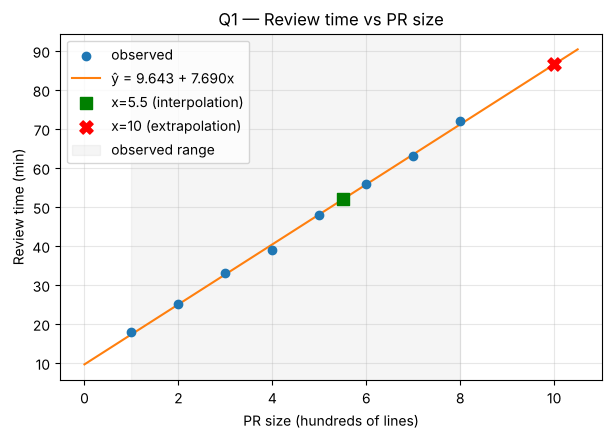

In [3]:
xs = np.linspace(0, 10.5, 200)
plt.figure(figsize=(7, 4.5))
plt.scatter(x1, y1, color="tab:blue", zorder=3, label="observed")
plt.plot(xs, predict(xs), color="tab:orange", label=f"ŷ = {beta0:.3f} + {beta1:.3f}x")
plt.scatter([5.5], [predict(5.5)], marker="s", color="green", s=70, zorder=4, label="x=5.5 (interpolation)")
plt.scatter([10], [predict(10)], marker="X", color="red", s=90, zorder=4, label="x=10 (extrapolation)")
plt.axvspan(1, 8, color="gray", alpha=0.08, label="observed range")
plt.xlabel("PR size (hundreds of lines)"); plt.ylabel("Review time (min)")
plt.title("Q1 — Review time vs PR size"); plt.legend(); plt.grid(alpha=.3); plt.show()

### c) Compare with the initial reasoning
- **Intercept $\beta_0 \approx 9.643$ min**: the fixed overhead of any review (opening the PR, reading the description, CI status) even for a tiny change. Note $x=0$ is outside the data, so it is a model artefact rather than a measured value.
- **Slope $\beta_1 \approx 7.690$ min**: each extra 100 changed lines adds about 7.7 minutes. The sign is **positive**, exactly as predicted.
- **Fit quality**: $R^2 \approx 0.999$, MSE $\approx 0.435$ — the relationship is almost perfectly linear inside the data range.
- **Predictions**: $\hat y(5.5) \approx 51.940$ min sits between the observed 48 (x=5) and 56 (x=6) — trustworthy. $\hat y(10) \approx 86.548$ min is a pure extrapolation: the model *gives* a number, but the high $R^2$ only describes $x\in[1,8]$, so it says nothing about whether the trend holds at 10. This confirms the initial reasoning that the $x=5.5$ prediction is safer.

---
## Question 2 — CI build time and model complexity

### Think first
- **Linear or curved?** Differences between consecutive build times are 1.9, 3.3, 4.4, 5.7, 7.4 — they **keep growing**, so the curve bends upward. The pattern looks **curved (roughly quadratic)**, not linear. A straight line will underestimate the ends and overestimate the middle.
- **Why near-zero training error is not automatically best.** Training error only measures how well the model reproduces the points it has already seen. A very flexible model can also fit the noise in those 6 points (overfitting) and then behave badly on new inputs, especially outside the range. The right model is the one with low error on **unseen** data — which requires a validation set or cross-validation, and a model whose shape makes physical sense.

In [4]:
x2 = np.array([1, 2, 3, 4, 5, 6], dtype=float)
y2 = np.array([5.2, 7.1, 10.4, 14.8, 20.5, 27.9])

def fit_ls(Phi, y):
    return np.linalg.lstsq(Phi, y, rcond=None)[0]

# Degree-1: phi(x) = [1, x]
Phi_lin = np.column_stack([np.ones_like(x2), x2])
w_lin = fit_ls(Phi_lin, y2)
# Feature map phi(x) = [1, x, x^2]
Phi_quad = np.column_stack([np.ones_like(x2), x2, x2**2])
w_quad = fit_ls(Phi_quad, y2)

mse_lin = np.mean((y2 - Phi_lin @ w_lin) ** 2)
mse_quad = np.mean((y2 - Phi_quad @ w_quad) ** 2)
print("Linear    weights [b0, b1]     =", r3(w_lin),  f"  MSE = {mse_lin:.3f}")
print("Quadratic weights [b0, b1, b2] =", r3(w_quad), f"  MSE = {mse_quad:.3f}")

Linear    weights [b0, b1]     = [-1.493  4.517]   MSE = 2.738
Quadratic weights [b0, b1, b2] = [ 4.69  -0.12   0.662]   MSE = 0.007


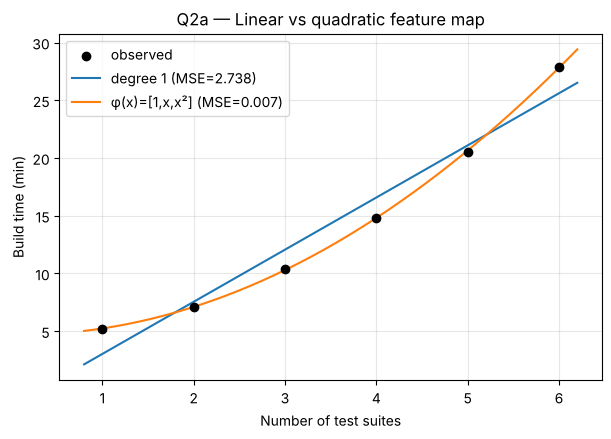

In [5]:
xs = np.linspace(0.8, 6.2, 200)
plt.figure(figsize=(7, 4.5))
plt.scatter(x2, y2, color="black", zorder=3, label="observed")
plt.plot(xs, w_lin[0] + w_lin[1]*xs, label=f"degree 1 (MSE={mse_lin:.3f})")
plt.plot(xs, w_quad[0] + w_quad[1]*xs + w_quad[2]*xs**2, label=f"φ(x)=[1,x,x²] (MSE={mse_quad:.3f})")
plt.xlabel("Number of test suites"); plt.ylabel("Build time (min)")
plt.title("Q2a — Linear vs quadratic feature map"); plt.legend(); plt.grid(alpha=.3); plt.show()

**Q2a comparison.** The quadratic feature map reduces the MSE from about **2.738** to **0.007**, confirming the curvature we saw in the growing differences. Here the extra $x^2$ term is justified: it has a plausible cause (e.g. test suites interacting / shared setup growing with suite count) and only adds one parameter. Still, with only 6 points, a near-zero training MSE is not proof of good generalisation — we would confirm it with held-out builds.

### Q2b — Gradient descent for $\hat y = \beta x$ (no intercept)
The loss $L(\beta)$ is a parabola in $\beta$ with curvature $\frac{2}{n}\sum x_i^2$. Gradient descent converges only if $\alpha < \dfrac{2}{\frac{2}{n}\sum x_i^2} = \dfrac{n}{\sum x_i^2}$. Below we compute that bound, pick a safe $\alpha$, and also show a too-large $\alpha$ for diagnosis.

In [6]:
n = len(x2)
L    = lambda b: np.mean((y2 - b * x2) ** 2)
dLdb = lambda b: -2 / n * np.sum(x2 * (y2 - b * x2))

beta_exact = (x2 @ y2) / (x2 @ x2)          # closed-form optimum for comparison
alpha_max  = n / np.sum(x2 ** 2)             # divergence threshold
print(f"Closed-form beta* = {beta_exact:.3f}")
print(f"Stability bound: alpha < {alpha_max:.3f}")

def gradient_descent(alpha, beta=0.0, iters=50, tol=1e-8):
    history = [L(beta)]
    for _ in range(iters):
        beta -= alpha * dLdb(beta)
        history.append(L(beta))
        if abs(history[-2] - history[-1]) < tol:
            break
    return beta, history

alpha = 0.03
beta_gd, hist = gradient_descent(alpha)
print(f"\nalpha = {alpha}: beta = {beta_gd:.3f}, final loss = {hist[-1]:.3f}, iterations = {len(hist)-1}")

beta_bad, hist_bad = gradient_descent(0.07, iters=15)
print(f"alpha = 0.07 (> bound): beta = {beta_bad:.3f}, loss after 15 iters = {hist_bad[-1]:.3f}  -> diverges")

Closed-form beta* = 4.173
Stability bound: alpha < 0.066

alpha = 0.03: beta = 4.173, final loss = 3.167, iterations = 6
alpha = 0.07 (> bound): beta = 28.052, loss after 15 iters = 8651.809  -> diverges


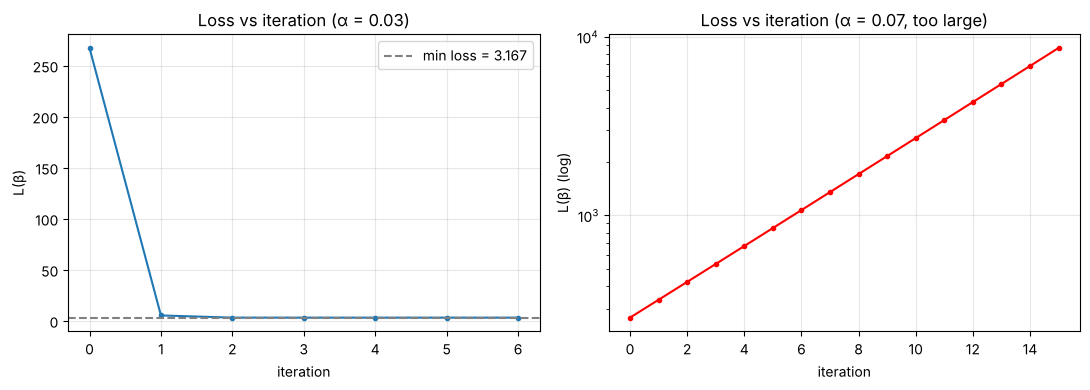

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist, marker="o", ms=3)
ax[0].axhline(L(beta_exact), ls="--", color="gray", label=f"min loss = {L(beta_exact):.3f}")
ax[0].set(title=f"Loss vs iteration (α = {alpha})", xlabel="iteration", ylabel="L(β)"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].semilogy(hist_bad, marker="o", ms=3, color="red")
ax[1].set(title="Loss vs iteration (α = 0.07, too large)", xlabel="iteration", ylabel="L(β) (log)"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

**Convergence diagnosis.**
- With $\alpha = 0.03$ (below the bound ≈ 0.066) the loss decreases **monotonically** and flattens out; $\beta$ reaches the closed-form optimum $\beta^* \approx 4.173$ after only a handful of iterations (the stopping rule triggers at iteration 6). This is convergence.
- With $\alpha = 0.07$ (above the bound) each step overshoots the minimum by more than it corrects, so $\beta$ oscillates with growing amplitude and the loss explodes — divergence.
- The remaining loss at the optimum is still ≈ 3.167 (vs 0.007 for the quadratic model) because $\hat y = \beta x$ is a line through the origin; it cannot capture the curvature from Q2a. GD found the best *possible* $\beta$ for this model — the limitation is the model, not the optimiser.

---
# Part II. Logistic Regression
## Question 3 — Deployment failure

### Think first
- **Why classification.** The target is a category — FAIL (1) or OK (0) — not a continuous quantity. We want $P(\text{FAIL}\mid x)\in[0,1]$, which a linear regression cannot guarantee; logistic regression passes a linear score through the sigmoid to get a valid probability.
- **Signs of the coefficients.** Both **positive**: larger changes ($x_1$) and higher test-failure rates ($x_2$) both make a failed deployment more likely, and in the table all failures have the larger values of both features.
- **Lowering the threshold** (e.g. 0.5 → 0.3): more deployments get flagged as FAIL, so **missed failures (false negatives) go down** but **false alarms (false positives) go up**. Raising the threshold does the opposite.

In [8]:
X3 = np.array([[.2, .1], [.5, .2], [.7, .4], [1, .7], [1.3, .9], [1.5, 1.1], [1.8, 1.4], [2, 1.7]])
y3 = np.array([0, 0, 0, 0, 1, 1, 1, 1])

sigmoid = lambda z: 1 / (1 + np.exp(-z))

# a) Train (sklearn default L2 regularisation, C=1, keeps coefficients finite on separable data)
clf3 = LogisticRegression().fit(X3, y3)
b0_3, (b1_3, b2_3) = clf3.intercept_[0], clf3.coef_[0]
print(f"beta0 = {b0_3:.3f}, beta1 (change size) = {b1_3:.3f}, beta2 (test-failure rate) = {b2_3:.3f}")

x_new = np.array([1.2, 0.8])
z_new = b0_3 + b1_3 * x_new[0] + b2_3 * x_new[1]
print(f"\nz = {z_new:.3f}")
print(f"P(FAIL | x=[1.2, 0.8]) = sigma(z) = {sigmoid(z_new):.3f}")
print(f"(sklearn predict_proba check: {clf3.predict_proba([x_new])[0, 1]:.3f})")

beta0 = -1.831, beta1 (change size) = 1.005, beta2 (test-failure rate) = 0.869

z = 0.070
P(FAIL | x=[1.2, 0.8]) = sigma(z) = 0.518
(sklearn predict_proba check: 0.518)


In [9]:
# b) Compare two thresholds
p3 = clf3.predict_proba(X3)[:, 1]
print("Training probabilities:", r3(p3), "\n")

for t in (0.5, 0.3):
    pred = (p3 >= t).astype(int)
    cm = confusion_matrix(y3, pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    print(f"Threshold = {t}")
    print("  confusion matrix [[TN FP] [FN TP]]:\n", cm)
    print(f"  false alarms (FP) = {fp}, missed failures (FN) = {fn}, accuracy = {accuracy_score(y3, pred):.3f}\n")

Training probabilities: [0.176 0.24  0.314 0.446 0.564 0.653 0.768 0.84 ] 

Threshold = 0.5
  confusion matrix [[TN FP] [FN TP]]:
 [[4 0]
 [0 4]]
  false alarms (FP) = 0, missed failures (FN) = 0, accuracy = 1.000

Threshold = 0.3
  confusion matrix [[TN FP] [FN TP]]:
 [[2 2]
 [0 4]]
  false alarms (FP) = 2, missed failures (FN) = 0, accuracy = 0.750



**Comparison with the reasoning.**
- Both coefficients came out **positive** (≈ 1.005 for change size, ≈ 0.869 for test-failure rate), as predicted.
- For $x=[1.2,0.8]$ the model gives $P(\text{FAIL})\approx 0.518$ — just above 0.5. This makes sense: the point lies between the last OK deployment (1.0, 0.7) and the first FAIL (1.3, 0.9), i.e. right at the decision boundary.
- **Threshold 0.5:** 0 false alarms, 0 missed failures, accuracy 1.000.
  **Threshold 0.3:** missed failures stay at 0, but **2 false alarms** appear (OK deployments with $p\approx 0.314$ and $0.446$), accuracy drops to 0.750.
- This is exactly the predicted trade-off: a lower threshold can only reduce missed failures, at the cost of more false alarms. In practice a team might still prefer a lower threshold if a failed production deploy is much more costly than an extra manual check.

---
## Question 4 — Logistic loss and one update

### Think first
- For $y=1$, the loss is $\ell = -\log p$. It is $0$ when $p\to 1$ and $\to\infty$ when $p\to 0$. So a probability **near 1 gives lower loss**.
- The gradient $(p-y)x$ points in the direction of increasing loss; stepping against it with a small learning rate should **decrease the loss**. Here $p - y < 0$, so the update adds a positive multiple of $x$ to $\beta$, which increases $z = \beta^Tx$ and pushes $p$ up toward 1.

In [10]:
x4 = np.array([1, 2, 1.5])
y4 = 1
beta_0 = np.array([0.1, -0.2, 0.3])
lr = 0.1

def bce(y, p):
    return -(y * np.log(p) + (1 - y) * np.log(1 - p))

# a) forward pass
z0 = beta_0 @ x4; p0 = sigmoid(z0); l0 = bce(y4, p0)
print(f"Before update: z = {z0:.3f}, p = {p0:.3f}, loss = {l0:.3f}")

# b) gradient and one GD step
grad = (p0 - y4) * x4
beta_1 = beta_0 - lr * grad
z1 = beta_1 @ x4; p1 = sigmoid(z1); l1 = bce(y4, p1)
print(f"Gradient      = {r3(grad)}")
print(f"beta(1)       = {r3(beta_1)}")
print(f"After update:  z = {z1:.3f}, p = {p1:.3f}, loss = {l1:.3f}")
print(f"Change: p {p0:.3f} -> {p1:.3f} (up), loss {l0:.3f} -> {l1:.3f} (down by {l0 - l1:.3f})")

Before update: z = 0.150, p = 0.537, loss = 0.621
Gradient      = [-0.463 -0.925 -0.694]
beta(1)       = [ 0.146 -0.107  0.369]
After update:  z = 0.485, p = 0.619, loss = 0.480
Change: p 0.537 -> 0.619 (up), loss 0.621 -> 0.480 (down by 0.141)


**Comparison.** Initially $z = 0.150$, $p \approx 0.537$, $\ell \approx 0.621$. The gradient is negative in every component (because $p-y<0$ and $x>0$), so the update increased every coefficient. After one step $z\approx 0.485$, $p \approx 0.619$ and $\ell \approx 0.480$: the probability moved toward the true label and the loss decreased — exactly as expected.

---
# Part III. Softmax Regression
## Question 5 — Softmax outputs

### Think first
- **Predicted classes** (largest logit per row, since softmax is monotone):
  Row 1 (1.2, **2.1**, 0.4) → **Backend**; Row 2 (**2.4**, 0.8, 0.5) → **Frontend**; Row 3 (0.3, 1.1, **2.2**) → **Database**; Row 4 (**1.5**, 1.4, 1.3) → **Frontend**, but with low confidence because the logits are almost equal.
- **Valid probability vector:** (1) every entry is non-negative, $p_k \ge 0$; (2) entries sum to one, $\sum_k p_k = 1$.
- **Adding a constant $c$ to every logit in a row should NOT change the probabilities**: $\frac{e^{z_k+c}}{\sum_j e^{z_j+c}} = \frac{e^c e^{z_k}}{e^c\sum_j e^{z_j}}$, the $e^c$ cancels. This is also the trick behind numerically stable softmax (subtract the row max).

In [11]:
classes5 = np.array(["Frontend", "Backend", "Database"])
Z = np.array([[1.2, 2.1, 0.4],
              [2.4, 0.8, 0.5],
              [0.3, 1.1, 2.2],
              [1.5, 1.4, 1.3]])

def softmax(Z):
    Z = np.atleast_2d(Z)
    Z_shift = Z - Z.max(axis=1, keepdims=True)   # numerical stability
    E = np.exp(Z_shift)
    return E / E.sum(axis=1, keepdims=True)

P5 = softmax(Z)
print("Probabilities [Frontend, Backend, Database]:\n", r3(P5))
print("\nargmax classes:", classes5[P5.argmax(axis=1)])
expected = ["Backend", "Frontend", "Database", "Frontend"]
print("Matches prediction:", list(classes5[P5.argmax(axis=1)]) == expected)

Probabilities [Frontend, Backend, Database]:
 [[0.256 0.629 0.115]
 [0.74  0.149 0.111]
 [0.101 0.225 0.675]
 [0.367 0.332 0.301]]

argmax classes: ['Backend' 'Frontend' 'Database' 'Frontend']
Matches prediction: True


In [12]:
# b) Row sums and invariance to adding a constant
print("Row sums:", r3(P5.sum(axis=1)), "| all non-negative:", bool((P5 >= 0).all()))

for c in (5, -3, 100):
    P_shift = softmax(Z + c)
    print(f"c = {c:>4}: max |P(Z+c) - P(Z)| = {np.abs(P_shift - P5).max():.3e}")

# Why stability matters: naive softmax with huge logits
naive = lambda Z: np.exp(Z) / np.exp(Z).sum(axis=1, keepdims=True)
with np.errstate(over="ignore", invalid="ignore"):
    print("\nNaive softmax on Z+1000 :", naive(Z[:1] + 1000))
print("Stable softmax on Z+1000:", r3(softmax(Z[:1] + 1000)))

Row sums: [1. 1. 1. 1.] | all non-negative: True
c =    5: max |P(Z+c) - P(Z)| = 1.110e-16
c =   -3: max |P(Z+c) - P(Z)| = 5.551e-17
c =  100: max |P(Z+c) - P(Z)| = 2.109e-15

Naive softmax on Z+1000 : [[nan nan nan]]
Stable softmax on Z+1000: [[0.256 0.629 0.115]]


**Comparison.** All four argmax classes match the predictions. Row 4 is the least confident (≈ 0.367 / 0.332 / 0.301), as expected from nearly equal logits; row 2 is the most confident Frontend prediction. Every row sums to 1.000 with non-negative entries. Adding $c = 5, -3, 100$ changes the probabilities by at most ~$10^{-16}$ (floating-point noise) — invariance confirmed. The naive formula overflows to `nan` at $Z+1000$ while the stable version gives the correct answer.

---
## Question 6 — Multiclass incident classification

### Think first
- **Why binary logistic is insufficient.** There are **three** classes (Frontend, Backend, Database). One sigmoid gives a single probability for a yes/no question; it cannot assign probability mass to three mutually exclusive outcomes. We need softmax regression (or several one-vs-rest models).
- **Outputs per sample:** **3** probabilities, one per class, summing to 1.
- **Confusions to inspect.** **Frontend vs Backend**: both have low database latency and are separated only by error rate ($x_1 \approx 0.8$–$1.1$ vs $1.4$–$1.6$), so they are closest in feature space. Database incidents are clearly separated by high latency $x_2$, so confusion with them is less likely. Operationally, Frontend ↔ Backend mistakes are also costly because they send the incident to the wrong on-call team.

In [13]:
classes6 = ["Frontend", "Backend", "Database"]
X6 = np.array([[.9, .2], [1.1, .3], [.8, .4], [1.4, .8], [1.6, .9], [1.5, .7], [.4, 1.5], [.5, 1.7], [.6, 1.4]])
y6 = np.array([0, 0, 0, 1, 1, 1, 2, 2, 2])

# a) multinomial (softmax) logistic regression — sklearn uses softmax for multiclass by default with lbfgs
clf6 = LogisticRegression().fit(X6, y6)
P6 = clf6.predict_proba(X6)
pred6 = P6.argmax(axis=1)

print("Sample | x1   x2  | true      | P(Front) P(Back) P(DB) | predicted")
for i, (xi, yi, pi, pr) in enumerate(zip(X6, y6, P6, pred6)):
    print(f"{i:>6} | {xi[0]:.1f}  {xi[1]:.1f} | {classes6[yi]:<9} | {pi[0]:.3f}    {pi[1]:.3f}   {pi[2]:.3f} | {classes6[pr]}")

cm6 = confusion_matrix(y6, pred6)
print("\nConfusion matrix (rows = true, cols = predicted; order Frontend, Backend, Database):\n", cm6)
print(f"Accuracy = {accuracy_score(y6, pred6):.3f}")

Sample | x1   x2  | true      | P(Front) P(Back) P(DB) | predicted
     0 | 0.9  0.2 | Frontend  | 0.589    0.267   0.144 | Frontend
     1 | 1.1  0.3 | Frontend  | 0.520    0.338   0.142 | Frontend
     2 | 0.8  0.4 | Frontend  | 0.534    0.263   0.203 | Frontend
     3 | 1.4  0.8 | Backend   | 0.307    0.496   0.197 | Backend
     4 | 1.6  0.9 | Backend   | 0.248    0.575   0.177 | Backend
     5 | 1.5  0.7 | Backend   | 0.317    0.524   0.159 | Backend
     6 | 0.4  1.5 | Database  | 0.167    0.158   0.675 | Database
     7 | 0.5  1.7 | Database  | 0.124    0.164   0.712 | Database
     8 | 0.6  1.4 | Database  | 0.195    0.214   0.591 | Database

Confusion matrix (rows = true, cols = predicted; order Frontend, Backend, Database):
 [[3 0 0]
 [0 3 0]
 [0 0 3]]
Accuracy = 1.000


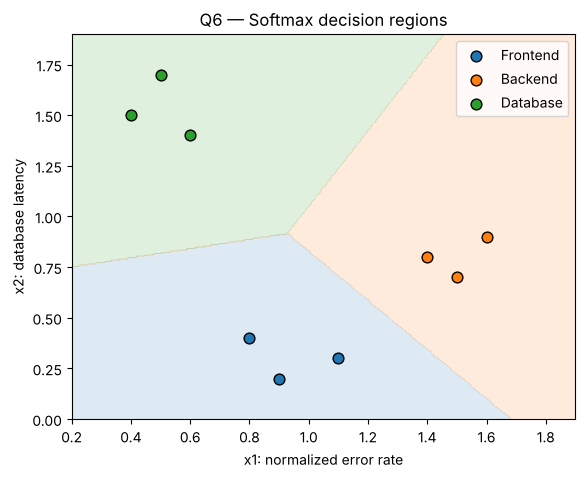

In [14]:
# Decision regions for intuition
xx, yy = np.meshgrid(np.linspace(0.2, 1.9, 300), np.linspace(0, 1.9, 300))
regions = clf6.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
plt.figure(figsize=(6.5, 5))
plt.contourf(xx, yy, regions, alpha=.15, levels=[-.5, .5, 1.5, 2.5], colors=["tab:blue", "tab:orange", "tab:green"])
for k, col in enumerate(["tab:blue", "tab:orange", "tab:green"]):
    plt.scatter(*X6[y6 == k].T, color=col, edgecolor="k", s=60, label=classes6[k])
plt.xlabel("x1: normalized error rate"); plt.ylabel("x2: database latency")
plt.title("Q6 — Softmax decision regions"); plt.legend(); plt.show()

In [15]:
# b) Multiclass log loss: mean of -log p_c over samples
per_sample = -np.log(P6[np.arange(len(y6)), y6])
print("Per-sample loss  -log p_c :", r3(per_sample))
print(f"Multiclass log loss (mean) = {per_sample.mean():.3f}")
print(f"sklearn log_loss check     = {log_loss(y6, P6):.3f}")

i = int(per_sample.argmax())
print(f"\nExample: sample {i}, true class = {classes6[y6[i]]}, p_c = {P6[i, y6[i]]:.3f}"
      f" -> contribution = -log({P6[i, y6[i]]:.3f}) = {per_sample[i]:.3f}  (largest of all samples)")
j = int(per_sample.argmin())
print(f"Example: sample {j}, true class = {classes6[y6[j]]}, p_c = {P6[j, y6[j]]:.3f}"
      f" -> contribution = {per_sample[j]:.3f}  (smallest)")

Per-sample loss  -log p_c : [0.53  0.654 0.628 0.701 0.553 0.647 0.393 0.34  0.526]
Multiclass log loss (mean) = 0.552
sklearn log_loss check     = 0.552

Example: sample 3, true class = Backend, p_c = 0.496 -> contribution = -log(0.496) = 0.701  (largest of all samples)
Example: sample 7, true class = Database, p_c = 0.712 -> contribution = 0.340  (smallest)


In [16]:
# c) Coefficient matrix
W = clf6.coef_; b = clf6.intercept_
print("Coefficient matrix W, shape", W.shape, "(classes x features):")
for k in range(3):
    print(f"  {classes6[k]:<9} w = {r3(W[k])}, intercept = {b[k]:.3f}")
print("Intercept vector shape:", b.shape)

Coefficient matrix W, shape (3, 2) (classes x features):
  Frontend  w = [-0.276 -1.012], intercept = 1.183
  Backend   w = [1.002 0.042], intercept = -0.969
  Database  w = [-0.727  0.97 ], intercept = -0.214
Intercept vector shape: (3,)


**Interpretation and comparison.**
- **a)** The model outputs **3 probabilities per sample** that sum to 1, as predicted. All 9 training samples are classified correctly (diagonal confusion matrix, accuracy 1.000). The predicted weak spot shows up in the probabilities rather than the labels: the least confident samples are Backend sample 3 ($p\approx0.496$) and Frontend sample 1 ($p\approx0.520$), whose runner-up class is each other — the **Frontend/Backend** pair we flagged. Database samples get the highest confidence (up to 0.712) thanks to their high latency.
- **b)** The mean multiclass log loss is **0.552**. It only looks at the probability assigned to the **true** class, $\ell_i=-\log p_{c}$. Sample 3 (true Backend, $p_c\approx0.496$) contributes $-\log 0.496\approx0.701$, the largest term; sample 7 (true Database, $p_c\approx0.712$) contributes only 0.340. Even though every prediction is correct, the loss is far from 0 because sklearn's default L2 regularisation keeps the probabilities moderate — log loss rewards *confidence*, not just correctness.
- **c)** $W$ has shape **3 × 2** (one row per class, one column per feature) plus a **3-element intercept** vector — 9 parameters in total. Each class needs its own weight vector because softmax computes a separate score $z_k = w_k^\top x + b_k$ for every class and compares them. The rows make sense: the **Database** row has the largest positive weight on $x_2$ (latency), the **Backend** row has the largest positive weight on $x_1$ (error rate), and Frontend is favoured when both are lower. A single shared vector could only rank samples along one direction and could not express "high latency → Database, high errors → Backend".